# Recurrent neural networks for nonlinear input--response forecasting

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/sequential-models/03-silverbox-rnn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

This notebook revisits the [Silverbox benchmark](https://www.nonlinearbenchmark.org/benchmarks/silverbox): an applied input `V1` drives a measured response `V2`. We retain the same forecasting protocol as the AR/ARX notebook, then replace the fixed, linear lag representation with a learned nonlinear recurrent state.


## What you will do

1. Reload the Silverbox training and held-out experiments.
2. Fit compact AR and ARX reference models under the same recursive forecasting protocol.
3. Train a response-only RNN: a nonlinear recurrent counterpart to AR.
4. Give the RNN the known forcing input: a nonlinear recurrent counterpart to ARX.
5. *(Optional)* Compare the input-aware RNN and an LSTM with the same inputs and scoring protocol.


## 1. Load the measured input--response experiments

The `nonlinear-benchmarks` package downloads the official Silverbox record to the notebook runtime. Nothing is fitted to the held-out experiment.


In [1]:
# This package downloads the official Silverbox benchmark when it is first used.
try:
    from nonlinear_benchmarks import Silverbox
except ModuleNotFoundError:
    %pip install -q nonlinear-benchmarks
    from nonlinear_benchmarks import Silverbox

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_SEED = 7
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Prefer an NVIDIA GPU (CUDA), then an Apple Silicon GPU (MPS), then the CPU.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"PyTorch device: {device}")


PyTorch device: mps


In [2]:
# Store the official download in the notebook's local working directory.
# In Colab, this directory is temporary and disappears when the runtime ends.
benchmark_directory = Path("silverbox-data")
benchmark_directory.mkdir(exist_ok=True)
training_record, test_records = Silverbox(dir_placement=benchmark_directory)
test_record = test_records[0]  # Select the held-out record.

u_train = np.asarray(training_record.u, dtype=float).reshape(-1)
y_train = np.asarray(training_record.y, dtype=float).reshape(-1)
u_test = np.asarray(test_record.u, dtype=float).reshape(-1)
y_test = np.asarray(test_record.y, dtype=float).reshape(-1)
sampling_time = float(training_record.sampling_time)

print(f"Training samples: {len(y_train):,}")
print(f"Held-out samples: {len(y_test):,}")
print(f"Sampling interval: {sampling_time * 1_000:.4f} ms")

# Keep the first recurrent-model exercise practical on a CPU runtime.
# Every model in this notebook uses this same chronological training prefix.
TRAINING_SAMPLES = 25_000
u_train_model = u_train[:TRAINING_SAMPLES]
y_train_model = y_train[:TRAINING_SAMPLES]
print(f"Training prefix used in this notebook: {TRAINING_SAMPLES:,} samples")


Training samples: 65,062
Held-out samples: 21,688
Sampling interval: 1.6384 ms
Training prefix used in this notebook: 25,000 samples


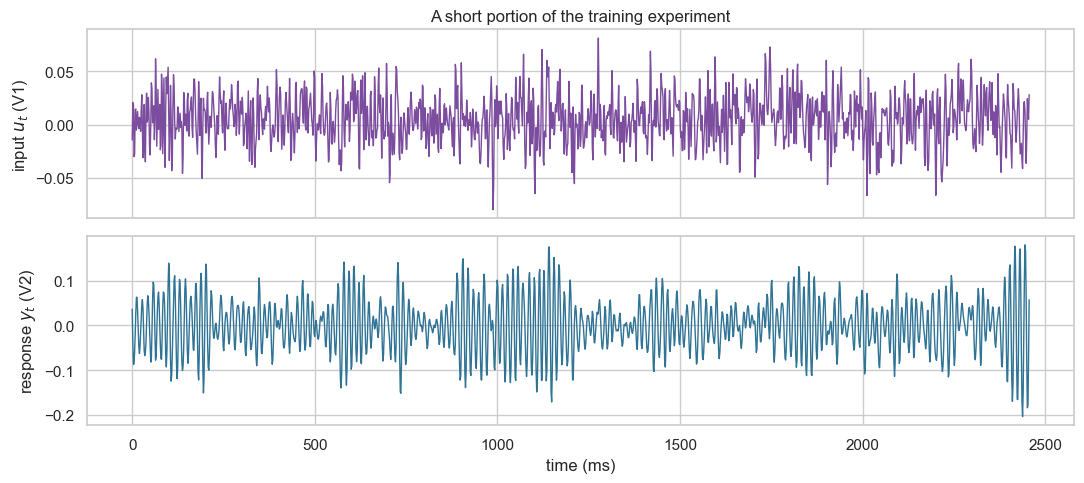

In [3]:
display_samples = 1_500
time_ms = np.arange(display_samples) * sampling_time * 1_000

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(time_ms, u_train[:display_samples], color="#7c4d9e", linewidth=1)
axes[0].set(ylabel="input $u_t$ (V1)", title="A short portion of the training experiment")
axes[1].plot(time_ms, y_train[:display_samples], color="#2f7395", linewidth=1)
axes[1].set(xlabel="time (ms)", ylabel="response $y_t$ (V2)")
plt.tight_layout()
plt.show()

## 2. Reuse the same forecasting protocol and linear references

We use **recursive multi-step forecasting** throughout. The final $p=20$ training responses initialize each model's lag history or recurrent state. The forecast begins at the first held-out sample; thereafter, predicted responses—not held-out labels—are reused as inputs. The forcing input `V1` remains known throughout the held-out experiment because it is externally imposed.

The AR and ARX models below are concise reference baselines. Their detailed construction is developed in the preceding AR/ARX notebook. To keep this first recurrent-model exercise practical on a CPU, every model is fitted on the same first 25,000 training samples. For initialization only, each model uses the final 20 observations of the complete training record, immediately before the test boundary. The intervening training observations are not used for fitting or warmup; all held-out samples are scored.


In [4]:
ORDER = 20


def make_linear_design(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[np.ndarray, np.ndarray]:
    """Build one-step input rows for an AR or ARX model."""
    rows: list[np.ndarray] = []
    targets: list[float] = []
    for index in range(order, len(output_signal)):
        response_lags = output_signal[index - order : index][::-1]
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            rows.append(np.concatenate((response_lags, input_lags)))
        else:
            rows.append(response_lags)
        targets.append(output_signal[index])
    return np.asarray(rows), np.asarray(targets)


def fit_linear_forecaster(
    *,
    input_signal: np.ndarray,
    output_signal: np.ndarray,
    order: int,
    include_input: bool,
) -> tuple[StandardScaler, LinearRegression]:
    """Fit a linear AR or ARX forecaster using training data only."""
    features, targets = make_linear_design(
        input_signal=input_signal,
        output_signal=output_signal,
        order=order,
        include_input=include_input,
    )
    scaler = StandardScaler().fit(features)
    model = LinearRegression().fit(scaler.transform(features), targets)
    return scaler, model


def recursive_linear_forecast(
    *,
    input_signal: np.ndarray,
    observed_output: np.ndarray,
    order: int,
    include_input: bool,
    scaler: StandardScaler,
    model: LinearRegression,
) -> np.ndarray:
    """Make a recursive multi-step forecast after an initial response window."""
    history = list(observed_output[:order])
    predictions = np.full(len(observed_output), np.nan)
    for index in range(order, len(observed_output)):
        response_lags = np.asarray(history[-order:][::-1])
        if include_input:
            input_lags = input_signal[index - order : index + 1][::-1]
            feature_row = np.concatenate((response_lags, input_lags))
        else:
            feature_row = response_lags
        prediction = model.predict(scaler.transform(feature_row.reshape(1, -1)))[0]
        history.append(float(prediction))
        predictions[index] = prediction
    return predictions


def rmse(*, actual: np.ndarray, predicted: np.ndarray, warmup: int) -> float:
    """Calculate root-mean-square error after the initialization window."""
    return float(np.sqrt(np.mean((actual[warmup:] - predicted[warmup:]) ** 2)))

# Only the final ORDER training observations initialize the forecast.
# Placeholder values make it explicit that held-out responses are not inputs.
forecast_input = np.concatenate((u_train[-ORDER:], u_test))
forecast_history = np.concatenate((y_train[-ORDER:], np.full(len(y_test), np.nan)))


In [5]:
ORDER = 20

ar_scaler, ar_model = fit_linear_forecaster(
    input_signal=u_train_model,
    output_signal=y_train_model,
    order=ORDER,
    include_input=False,
)
ar_prediction = recursive_linear_forecast(
    input_signal=forecast_input,
    observed_output=forecast_history,
    order=ORDER,
    include_input=False,
    scaler=ar_scaler,
    model=ar_model,
)[ORDER:]
ar_rmse = rmse(actual=y_test, predicted=ar_prediction, warmup=0)

arx_scaler, arx_model = fit_linear_forecaster(
    input_signal=u_train_model,
    output_signal=y_train_model,
    order=ORDER,
    include_input=True,
)
arx_prediction = recursive_linear_forecast(
    input_signal=forecast_input,
    observed_output=forecast_history,
    order=ORDER,
    include_input=True,
    scaler=arx_scaler,
    model=arx_model,
)[ORDER:]
arx_rmse = rmse(actual=y_test, predicted=arx_prediction, warmup=0)

print(f"AR({ORDER}) recursive multi-step held-out RMSE: {ar_rmse:.5f}")
print(f"ARX({ORDER}) recursive multi-step held-out RMSE: {arx_rmse:.5f}")

window_start = 6_000
window_length = 900
window = slice(window_start, window_start + window_length)
window_time = np.arange(window_start, window_start + window_length) * sampling_time * 1_000
zoom_window_start = window_start + window_length // 2 - 60
zoom_window_length = 120
zoom_window = slice(zoom_window_start, zoom_window_start + zoom_window_length)
zoom_time = np.arange(zoom_window_start, zoom_window_start + zoom_window_length) * sampling_time * 1_000


AR(20) recursive multi-step held-out RMSE: 0.05427
ARX(20) recursive multi-step held-out RMSE: 0.00695


## 3. Learn a nonlinear state from the response alone

A **recurrent neural network (RNN)** extends the MLP idea to sequential data. An MLP applies a learned transformation once to one fixed input vector. An RNN instead applies the **same learned transformation** repeatedly as it moves through a sequence.

This first RNN is response-only: at time $t$, it receives $y_{t-1}$ and its previous hidden state $\mathbf{h}_{t-1}$, but it does **not** see `V1`. It therefore has the same type of observed response information as AR. The difference is how it represents history: AR retains 20 explicit lags and combines them linearly, whereas the RNN compresses earlier information into a learned nonlinear state.

$$
\mathbf{h}_t = \tanh(W_h \mathbf{h}_{t-1} + W_y y_{t-1} + b_h),
\qquad \widehat{y}_t = f(\mathbf{h}_t).
$$

The hidden state is a learned vector of internal memory: it is not a measured physical state, but it can summarize useful information from earlier positions in the sequence. In this notebook it has $m=16$ entries, so the learned parameters have these shapes:

- $\mathbf{h}_t \in \mathbb{R}^{m}$ is the hidden-state vector.
- $W_h \in \mathbb{R}^{m\times m}$ maps the previous hidden state to the next one.
- $W_y \in \mathbb{R}^{m\times 1}$ maps the scalar prior response $y_{t-1}$ into the hidden state.
- $b_h \in \mathbb{R}^{m}$ is a bias vector.

The notation $f:\mathbb{R}^{m}\to\mathbb{R}$ leaves the readout architecture open. It could be an MLP, for example, but in this notebook we choose the simpler **linear readout**:

$$
f(\mathbf{h}_t) = \mathbf{w}_o^T\mathbf{h}_t+b_o,
\qquad \mathbf{w}_o\in\mathbb{R}^{m},\quad b_o\in\mathbb{R}.
$$

The recurrent state update is already nonlinear because of $\tanh$, so a linear readout still gives a nonlinear forecasting model. Using it here keeps the source of the model's temporal and nonlinear behavior clear.

We use $\tanh$ for the hidden-state activation because it is smooth, zero-centered, and bounded between $-1$ and $1$. Those properties preserve the sign of a state value while keeping repeated state updates from growing without bound. A sigmoid is also bounded, but it maps every value into $(0,1)$ and is not zero-centered; it is more commonly used as a gate in an LSTM. ReLU is common in MLPs and CNNs, but it is unbounded, so repeatedly applying it in a recurrent state can make the state unstable. None of this eliminates vanishing gradients: $\tanh$ can also shrink gradients when it saturates.

### Sequence-to-sequence next-step forecasting

This is a **sequence-to-sequence** model: it makes one next-response prediction at **every** time step, not only one prediction from the final state. For the response-only model, a training segment is

$$
[y_0, y_1, \ldots, y_{T-1}]\;\longmapsto\;[\widehat{y}_1, \widehat{y}_2, \ldots, \widehat{y}_T].
$$

At each step, the RNN produces a hidden state $\mathbf{h}_t$, and the same linear readout produces $\widehat y_t=f(\mathbf{h}_t)$. We therefore retain all $T$ hidden states and compare all $T$ predictions with their targets during training. A **sequence-to-one** design would use only the final state $\mathbf{h}_T$ to make one prediction for the entire segment; that is not the task here. The input-aware RNN follows the same pattern, but its time-$t$ input is $[u_t, y_{t-1}]$.

### Keep the two lengths separate

<table style="width: 100%; table-layout: fixed; border-collapse: collapse;">
<colgroup>
<col style="width: 22%;">
<col style="width: 12%;">
<col style="width: 66%;">
</colgroup>
<thead><tr><th style="border: 1px solid #c9d6df; background: #e9f2f7; padding: 0.45rem 0.65rem; vertical-align: top;">Quantity</th><th style="border: 1px solid #c9d6df; background: #e9f2f7; padding: 0.45rem 0.65rem; vertical-align: top;">Value here</th><th style="border: 1px solid #c9d6df; background: #e9f2f7; padding: 0.45rem 0.65rem; vertical-align: top;">Role</th></tr></thead>
<tbody>
<tr><td style="border: 1px solid #c9d6df; padding: 0.45rem 0.65rem; vertical-align: top;">AR/ARX order</td><td style="border: 1px solid #c9d6df; padding: 0.45rem 0.65rem; vertical-align: top;">20</td><td style="border: 1px solid #c9d6df; padding: 0.45rem 0.65rem; vertical-align: top;">The number of explicit previous <code>V2</code> values used as linear features.</td></tr>
<tr><td style="border: 1px solid #c9d6df; padding: 0.45rem 0.65rem; vertical-align: top;">RNN warmup</td><td style="border: 1px solid #c9d6df; padding: 0.45rem 0.65rem; vertical-align: top;">20</td><td style="border: 1px solid #c9d6df; padding: 0.45rem 0.65rem; vertical-align: top;">The number of observed <code>V2</code> values that prime the RNN state before its recursive forecast is scored. This makes the held-out initialization comparable with AR/ARX.</td></tr>
<tr><td style="border: 1px solid #c9d6df; padding: 0.45rem 0.65rem; vertical-align: top;">RNN training chunk length</td><td style="border: 1px solid #c9d6df; padding: 0.45rem 0.65rem; vertical-align: top;">256</td><td style="border: 1px solid #c9d6df; padding: 0.45rem 0.65rem; vertical-align: top;">The maximum number of consecutive time steps through which gradients travel in one truncated-BPTT update. It does <strong>not</strong> reset the numerical hidden state or impose a 256-step memory limit.</td></tr>
</tbody>
</table>

Before the held-out recursive forecast, the final 20 training responses **prime** the hidden state. The model then advances one time step at a time, using its prior **predicted** response to obtain both the next prediction and the next hidden state. During training, it uses the observed prior response—called *teacher forcing*—and carries its state forward through the training record. We detach the state every 256 positions, so gradients travel through one chunk rather than the entire record; this is truncated backpropagation through time.

In [6]:
class RecurrentPredictor(torch.nn.Module):
    """Process a sequence while carrying a recurrent state.

    Args:
        input_size: Number of values supplied at each time step.
        hidden_size: Number of values carried by the learned recurrent state.
    """

    def __init__(self, *, input_size: int, hidden_size: int) -> None:
        super().__init__()
        # Make the one-layer, forward-only architecture explicit rather than
        # relying on PyTorch's defaults.
        self.rnn = torch.nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            bias=True,
            nonlinearity="tanh",
            bidirectional=False,
        )
        # A simple linear map f(h_t) = w_o^T h_t + b_o converts each learned
        # hidden-state vector into one next-response prediction.
        self.readout = torch.nn.Linear(hidden_size, 1)

    def forward(
        self,
        sequence: torch.Tensor,
        hidden_state: torch.Tensor | None = None,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """Predict standardized responses and return the state for the next step.

        Args:
            sequence: Tensor of shape `(time, input_size)`.
            hidden_state: State from the preceding sequence with shape
                `(1, hidden_size)`, or `None`. For `None`, PyTorch
                creates an all-zero initial state.

        Returns:
            Standardized predictions with shape `(time,)` and the next
            hidden state with shape `(1, hidden_size)`.
        """
        # hidden_values contains one hidden vector for *every* input time step:
        # (time, hidden_size). next_hidden_state contains only the
        # final vector h_T, retained so another chunk can continue the sequence.
        hidden_values, next_hidden_state = self.rnn(sequence, hidden_state)
        # Apply the same linear readout to every hidden vector, producing one
        # scalar standardized-response prediction per time step.
        predictions = self.readout(hidden_values).squeeze(-1)
        return predictions, next_hidden_state


def make_teacher_forced_sequence(
    *,
    input_signal: np.ndarray | None,
    output_signal: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """Create chronological RNN inputs and next-response targets.

    Args:
        input_signal: Standardized known forcing signal, or `None` for a response-only RNN.
        output_signal: Standardized response signal.

    Returns:
        Inputs containing either `[y_(t-1)]` or `[u_t, y_(t-1)]`, plus targets `y_t`.
    """
    if input_signal is None:
        # Response-only RNN: each row at time t contains y_(t-1).  The
        # trailing None creates a one-feature column with shape (time, 1).
        inputs = output_signal[:-1, None]
    else:
        # Input-aware RNN: each row is [u_t, y_(t-1)].  u_t is known when
        # predicting y_t; y_(t-1) is observed during teacher-forced training.
        inputs = np.column_stack((input_signal[1:], output_signal[:-1]))
    # Every input row is paired with the next response y_t.
    targets = output_signal[1:]
    return inputs.astype(np.float32), targets.astype(np.float32)


def detach_recurrent_state(
    hidden_state: torch.Tensor | tuple[torch.Tensor, torch.Tensor],
) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
    """Keep state values but remove their old gradient history."""
    if isinstance(hidden_state, tuple):
        # An LSTM carries (hidden_state, cell_state); detach both tensors.
        return tuple(value.detach() for value in hidden_state)
    # detaching preserves the numerical state while preventing gradients from
    # crossing into an earlier training chunk.
    return hidden_state.detach()


def train_stateful_sequence_model(
    *,
    model: torch.nn.Module,
    inputs: np.ndarray,
    targets: np.ndarray,
    epochs: int,
    chunk_size: int,
) -> list[float]:
    """Train an RNN or LSTM chronologically with truncated backpropagation.

    Args:
        model: Sequence model whose output is one standardized response per time step.
        inputs: Chronological tensor with shape `(time, features)`.
        targets: Standardized next-response targets with shape `(time,)`.
        epochs: Number of passes through the chronological training record.
        chunk_size: Number of time steps through which gradients are propagated.

    Returns:
        The mean chunk MSE after each epoch.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003, weight_decay=1e-5)
    # MSELoss averages the squared errors across the time steps in each chunk.
    loss_function = torch.nn.MSELoss()
    training_losses: list[float] = []

    for _ in range(epochs):
        model.train()
        chunk_losses: list[float] = []
        # Each new epoch begins from an all-zero state.  PyTorch creates it on
        # the first model call because hidden_state is None.
        hidden_state = None
        for start in range(0, len(inputs), chunk_size):
            stop = min(start + chunk_size, len(inputs))
            # One chronological sequence segment with shape (time, features).
            sequence_chunk = torch.from_numpy(inputs[start:stop]).to(device)
            # Its next-response targets have shape (time,).
            target_chunk = torch.from_numpy(targets[start:stop]).to(device)
            optimizer.zero_grad()  # PyTorch otherwise accumulates gradients from earlier chunks.
            # Carry the final state from the prior chunk, so the numerical
            # forward pass behaves as one continuous chronological sequence.
            prediction_chunk, hidden_state = model(sequence_chunk, hidden_state)
            loss = loss_function(prediction_chunk, target_chunk)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            # Carry the numerical state onward, but stop gradients at this boundary.
            hidden_state = detach_recurrent_state(hidden_state)
            chunk_losses.append(loss.item())
        training_losses.append(float(np.mean(chunk_losses)))

    return training_losses


def recursive_stateful_forecast(
    *,
    model: torch.nn.Module,
    input_signal: np.ndarray | None,
    observed_output: np.ndarray,
    warmup: int,
    input_mean: float | None,
    input_std: float | None,
    output_mean: float,
    output_std: float,
) -> np.ndarray:
    """Make a state-carrying recursive forecast.

    Args:
        model: Trained RNN or LSTM that predicts standardized responses.
        input_signal: Known held-out forcing signal, or `None` for response-only recurrence.
        observed_output: Held-out response; only the first `warmup` values prime state.
        warmup: Number of observed held-out values used before recursive prediction.
        input_mean: Training-input mean when `input_signal` is supplied.
        input_std: Training-input standard deviation when `input_signal` is supplied.
        output_mean: Training-output mean.
        output_std: Training-output standard deviation.

    Returns:
        Recursive predictions aligned with the held-out response.
    """
    predictions = np.full(len(observed_output), np.nan)

    def step_input(*, index: int, previous_response: float) -> torch.Tensor:
        standardized_response = (previous_response - output_mean) / output_std
        if input_signal is None:
            values = [standardized_response]
        else:
            standardized_input = (input_signal[index] - input_mean) / input_std
            values = [standardized_input, standardized_response]
        # Shape (1, features): one time step and either one
        # response feature or the two features [known input, prior response].
        return torch.tensor(values, dtype=torch.float32, device=device).reshape(1, -1)

    model.eval()
    with torch.no_grad():
        # Start from PyTorch's all-zero state, then replace it by a state
        # formed from the observed warmup history.
        hidden_state = None
        # Prime the recurrent state with the final training responses.
        for index in range(1, warmup):
            _, hidden_state = model(
                step_input(index=index, previous_response=float(observed_output[index - 1])),
                hidden_state,
            )

        # The final observed warmup response supplies the input for the first
        # forecast.  Thereafter, previous_response is the model's own forecast.
        previous_response = float(observed_output[warmup - 1])
        for index in range(warmup, len(observed_output)):
            standardized_prediction, hidden_state = model(
                step_input(index=index, previous_response=previous_response),
                hidden_state,
            )
            # Convert from the standardized model output before feeding this
            # recursive forecast back at the next time step.
            previous_response = standardized_prediction.item() * output_std + output_mean
            predictions[index] = previous_response
    return predictions

In [7]:
# Standardization statistics are learned from the training experiment only.
# The response-only RNN has one feature at each step: the preceding response.
y_mean, y_std = float(y_train_model.mean()), float(y_train_model.std())
y_train_scaled = (y_train_model - y_mean) / y_std

response_rnn_inputs, response_rnn_targets = make_teacher_forced_sequence(
    input_signal=None,
    output_signal=y_train_scaled,
)

HIDDEN_SIZE = 16
# Twenty epochs keep this first RNN exercise practical on a CPU runtime.
EPOCHS = 20
# This is the truncated-BPTT horizon, not the AR/ARX order or the test warmup.
CHUNK_SIZE = 256

torch.manual_seed(RANDOM_SEED)
response_rnn_model = RecurrentPredictor(input_size=1, hidden_size=HIDDEN_SIZE).to(device)
response_rnn_training_losses = train_stateful_sequence_model(
    model=response_rnn_model,
    inputs=response_rnn_inputs,
    targets=response_rnn_targets,
    epochs=EPOCHS,
    chunk_size=CHUNK_SIZE,
)

for epoch in range(10, EPOCHS + 1, 10):
    print(
        f"Response-only RNN epoch {epoch:>3}: "
        f"mean chunk MSE = {response_rnn_training_losses[epoch - 1]:.5f}"
    )

Response-only RNN epoch  10: mean chunk MSE = 0.00832
Response-only RNN epoch  20: mean chunk MSE = 0.00360


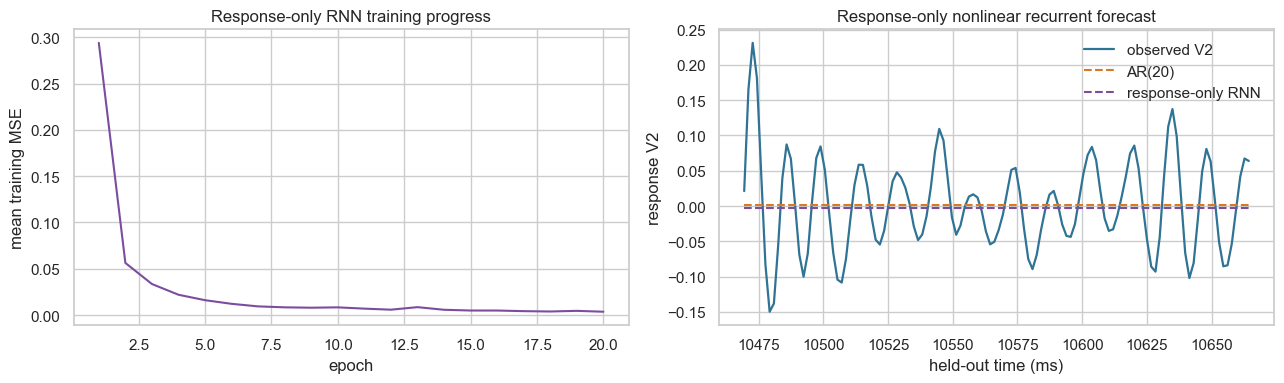

Response-only RNN recursive multi-step held-out RMSE: 0.05434


In [8]:
response_rnn_prediction = recursive_stateful_forecast(
    model=response_rnn_model,
    input_signal=None,
    observed_output=forecast_history,
    warmup=ORDER,
    input_mean=None,
    input_std=None,
    output_mean=y_mean,
    output_std=y_std,
)[ORDER:]
response_rnn_rmse = rmse(
    actual=y_test,
    predicted=response_rnn_prediction,
    warmup=0,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(
    np.arange(1, EPOCHS + 1),
    response_rnn_training_losses,
    color="#7c4d9e",
)
axes[0].set(
    xlabel="epoch",
    ylabel="mean training MSE",
    title="Response-only RNN training progress",
)

axes[1].plot(
    zoom_time,
    y_test[zoom_window],
    color="#2f7395",
    linewidth=1.6,
    label="observed V2",
)
axes[1].plot(
    zoom_time,
    ar_prediction[zoom_window],
    color="#d97927",
    linestyle="--",
    label="AR(20)",
)
axes[1].plot(
    zoom_time,
    response_rnn_prediction[zoom_window],
    color="#7c4d9e",
    linestyle="--",
    label="response-only RNN",
)
axes[1].set(
    xlabel="held-out time (ms)",
    ylabel="response V2",
    title="Response-only nonlinear recurrent forecast",
)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

print(
    "Response-only RNN recursive multi-step held-out RMSE: "
    f"{response_rnn_rmse:.5f}"
)

## 4. Give the RNN the known forcing input

The response-only RNN above is the recurrent analogue of AR: it only sees prior `V2` values. It cannot react directly when the applied excitation `V1` changes.

We now add the known forcing signal. At time $t$, the RNN receives the two-value input $[u_t, y_{t-1}]$ together with its prior hidden state:

$$
\mathbf{h}_t = \tanh(W_h \mathbf{h}_{t-1} + W_y y_{t-1} + W_u u_t + b_h),
\qquad \widehat{y}_t = f(\mathbf{h}_t).
$$

The earlier parameter shapes remain the same, and the additional matrix $W_u \in \mathbb{R}^{m\times 1}$ maps the scalar known input $u_t$ into the $m$-entry hidden state.

This is an **input-aware RNN**: the nonlinear recurrent counterpart to ARX. It has the same causal information pattern as ARX—the known current forcing signal and response history—but represents that history with a learned nonlinear state rather than a fixed, linear list of lags. The same teacher-forced training and state-carrying recursive held-out protocol apply.

In [9]:
# The input-aware RNN uses [current V1, previous V2] at every time step.
# Standardize V1 using the training experiment only.
u_mean, u_std = float(u_train_model.mean()), float(u_train_model.std())
u_train_scaled = (u_train_model - u_mean) / u_std

input_rnn_inputs, input_rnn_targets = make_teacher_forced_sequence(
    input_signal=u_train_scaled,
    output_signal=y_train_scaled,
)

# Use the same hidden size, chronological training record, and training budget.
torch.manual_seed(RANDOM_SEED)
rnn_model = RecurrentPredictor(input_size=2, hidden_size=HIDDEN_SIZE).to(device)
rnn_training_losses = train_stateful_sequence_model(
    model=rnn_model,
    inputs=input_rnn_inputs,
    targets=input_rnn_targets,
    epochs=EPOCHS,
    chunk_size=CHUNK_SIZE,
)

for epoch in range(10, EPOCHS + 1, 10):
    print(
        f"Input-aware RNN epoch {epoch:>3}: "
        f"mean chunk MSE = {rnn_training_losses[epoch - 1]:.5f}"
    )

Input-aware RNN epoch  10: mean chunk MSE = 0.00087
Input-aware RNN epoch  20: mean chunk MSE = 0.00031


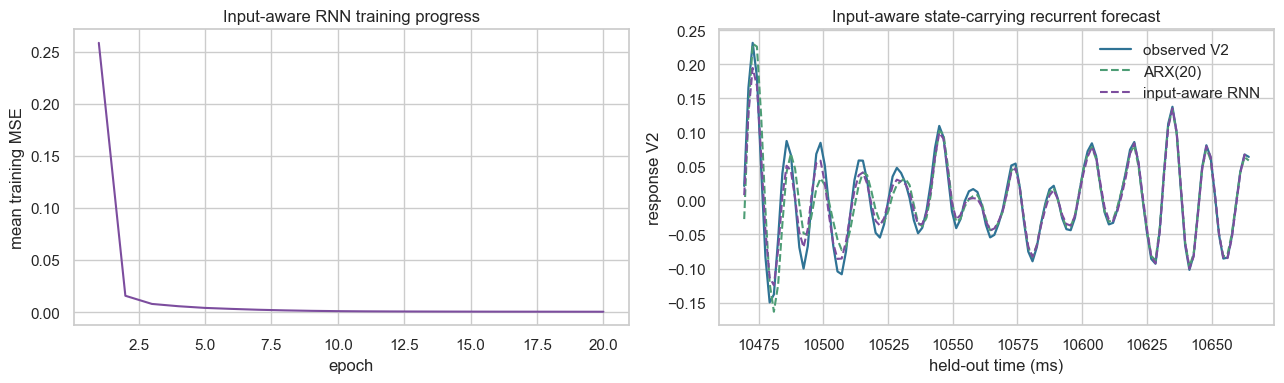

Input-aware RNN recursive multi-step held-out RMSE: 0.00327


In [10]:
rnn_prediction = recursive_stateful_forecast(
    model=rnn_model,
    input_signal=forecast_input,
    observed_output=forecast_history,
    warmup=ORDER,
    input_mean=u_mean,
    input_std=u_std,
    output_mean=y_mean,
    output_std=y_std,
)[ORDER:]
rnn_rmse = rmse(actual=y_test, predicted=rnn_prediction, warmup=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, EPOCHS + 1), rnn_training_losses, color="#7c4d9e")
axes[0].set(
    xlabel="epoch",
    ylabel="mean training MSE",
    title="Input-aware RNN training progress",
)

axes[1].plot(
    zoom_time,
    y_test[zoom_window],
    color="#2f7395",
    linewidth=1.6,
    label="observed V2",
)
axes[1].plot(
    zoom_time,
    arx_prediction[zoom_window],
    color="#4d9d75",
    linestyle="--",
    label="ARX(20)",
)
axes[1].plot(
    zoom_time,
    rnn_prediction[zoom_window],
    color="#7c4d9e",
    linestyle="--",
    label="input-aware RNN",
)
axes[1].set(
    xlabel="held-out time (ms)",
    ylabel="response V2",
    title="Input-aware state-carrying recurrent forecast",
)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

print(f"Input-aware RNN recursive multi-step held-out RMSE: {rnn_rmse:.5f}")

## 5. (Optional) Compare the input-aware RNN with an LSTM

An **LSTM (long short-term memory)** network is another recurrent architecture. Like the input-aware RNN above, it reads the same chronological input--response record and produces one next-response prediction at a time. Its gates control what information is stored, forgotten, and exposed through a separate cell state.

To isolate the architectural change, the comparison below keeps the 20-training-response warmup, 16 hidden values, optimizer, learning rate, epochs, truncated-backpropagation chunk length, and recursive held-out protocol fixed. The LSTM has more learned values because its gates add parameters, so this is a controlled illustration—not a claim of equal model capacity or a guarantee that an LSTM will always win.

In [11]:
class LSTMPredictor(torch.nn.Module):
    """Process an input--response sequence with an LSTM.

    Args:
        hidden_size: Number of values in the hidden and cell states.
    """

    def __init__(self, *, hidden_size: int) -> None:
        super().__init__()
        # One forward-only LSTM layer.  Each time step receives [u_t, y_(t-1)]
        # and maintains both a hidden state and a separate cell state.
        self.lstm = torch.nn.LSTM(
            input_size=2,  # [known input, previous response]
            hidden_size=hidden_size,
            num_layers=1,
            bias=True,
            bidirectional=False,
        )
        # Keep the output map linear so this comparison isolates the recurrent
        # cell architecture (ordinary RNN versus LSTM).
        self.readout = torch.nn.Linear(hidden_size, 1)

    def forward(
        self,
        sequence: torch.Tensor,
        hidden_state: tuple[torch.Tensor, torch.Tensor] | None = None,
    ) -> tuple[torch.Tensor, tuple[torch.Tensor, torch.Tensor]]:
        """Predict responses and return the hidden and cell states for the next step."""
        # hidden_values contains the last-layer hidden vector at every time
        # step: (time, hidden_size). next_hidden_state is the tuple
        # (h_T, c_T), each with shape (1, hidden_size). Passing None
        # makes PyTorch initialize both h_0 and c_0 to zero.
        hidden_values, next_hidden_state = self.lstm(sequence, hidden_state)
        predictions = self.readout(hidden_values).squeeze(-1)
        return predictions, next_hidden_state

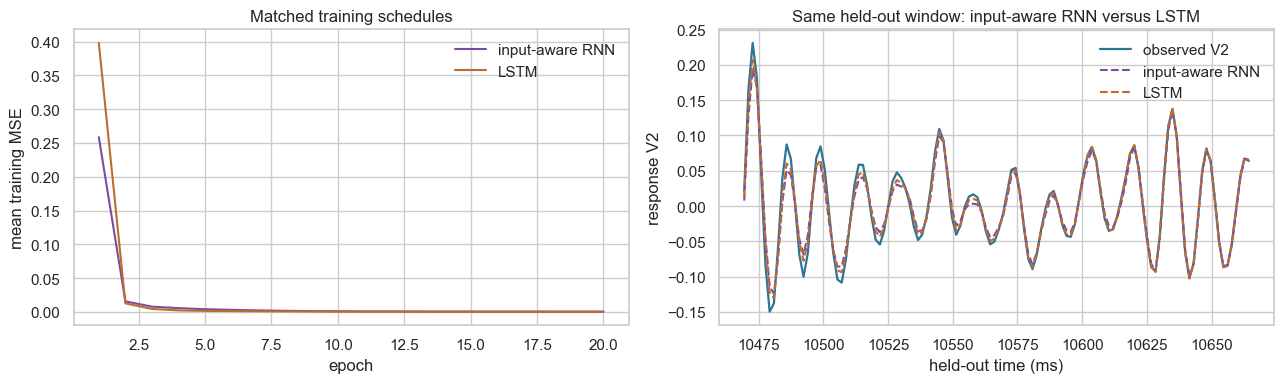

,model,information available,recursive multi-step held-out RMSE
0,AR(20),past response only,0.05427
1,ARX(20),past response + known forcing input,0.00695
2,response-only RNN,prior response + carried nonlinear state,0.05434
3,input-aware RNN,known forcing input + prior response + carried nonlinear state,0.00327
4,small LSTM,"same inputs + carried, gated hidden and cell states",0.00213


In [12]:
# Use the same random seed, chronological data, and truncated-BPTT chunks as the input-aware RNN.
torch.manual_seed(RANDOM_SEED)
lstm_model = LSTMPredictor(hidden_size=HIDDEN_SIZE).to(device)
lstm_training_losses = train_stateful_sequence_model(
    model=lstm_model,
    inputs=input_rnn_inputs,
    targets=input_rnn_targets,
    epochs=EPOCHS,
    chunk_size=CHUNK_SIZE,
)

lstm_prediction = recursive_stateful_forecast(
    model=lstm_model,
    input_signal=forecast_input,
    observed_output=forecast_history,
    warmup=ORDER,
    input_mean=u_mean,
    input_std=u_std,
    output_mean=y_mean,
    output_std=y_std,
)[ORDER:]
lstm_rmse = rmse(actual=y_test, predicted=lstm_prediction, warmup=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, EPOCHS + 1), rnn_training_losses, color="#7c4d9e", label="input-aware RNN")
axes[0].plot(np.arange(1, EPOCHS + 1), lstm_training_losses, color="#bd6b30", label="LSTM")
axes[0].set(xlabel="epoch", ylabel="mean training MSE", title="Matched training schedules")
axes[0].legend(frameon=False)

axes[1].plot(zoom_time, y_test[zoom_window], color="#2f7395", linewidth=1.6, label="observed V2")
axes[1].plot(zoom_time, rnn_prediction[zoom_window], color="#7c4d9e", linestyle="--", label="input-aware RNN")
axes[1].plot(zoom_time, lstm_prediction[zoom_window], color="#bd6b30", linestyle="--", label="LSTM")
axes[1].set(xlabel="held-out time (ms)", ylabel="response V2", title="Same held-out window: input-aware RNN versus LSTM")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "model": [
        f"AR({ORDER})",
        f"ARX({ORDER})",
        "response-only RNN",
        "input-aware RNN",
        "small LSTM",
    ],
    "information available": [
        "past response only",
        "past response + known forcing input",
        "prior response + carried nonlinear state",
        "known forcing input + prior response + carried nonlinear state",
        "same inputs + carried, gated hidden and cell states",
    ],
    "recursive multi-step held-out RMSE": [
        ar_rmse,
        arx_rmse,
        response_rnn_rmse,
        rnn_rmse,
        lstm_rmse,
    ],
})
display(comparison.style.format({"recursive multi-step held-out RMSE": "{:.5f}"}))

## 6. What this comparison does—and does not—show

- Adding `V1` helps because it is a known causal input that drives the system; neither AR nor the response-only RNN can react to it directly.
- The response-only RNN changes the representation of response history—from explicit linear lags to a learned nonlinear state—but it does not add new measured information.
- The input-aware RNN can learn nonlinear effects while using the known forcing signal, which is useful for this Duffing-like system.
- The LSTM adds gates that can preserve useful information, but it does **not** guarantee lower held-out error; its result here depends on this data and training configuration.
- The fair comparison is always on future or held-out experiments, with only information available at the forecasting time.


<p style="margin-top: 1.5rem;"><a href="index.html">← Return to Sequential models</a></p>